# P281 Homework Set 2
2026-10-15 hw2_10_15.ipynb Bella K

In [188]:
import numpy as np
from numpy import pi, sqrt, cos, sin, exp
import matplotlib.pyplot as plt
import pandas as pd
import scipy

## Question 1
Gezerlis 1.1 Recursive vs. iterative

In [189]:
def fact(n):
    '''recursive function that computes n! from Gezerlis 1.1'''
    return 1 if n == 0 else n * fact(n - 1)

In [190]:
def fact_iter(n):
    '''computes n! iteratively'''
    f = 1
    for i in range(1, n + 1):
        f = f * i
    return f

In [191]:
print('iteratively:')
for i in range(20):
    print(i, fact_iter(i))

iteratively:
0 1
1 1
2 2
3 6
4 24
5 120
6 720
7 5040
8 40320
9 362880
10 3628800
11 39916800
12 479001600
13 6227020800
14 87178291200
15 1307674368000
16 20922789888000
17 355687428096000
18 6402373705728000
19 121645100408832000


In [192]:
print('recursively:')
for i in range(20):
    print(i, fact(i))

recursively:
0 1
1 1
2 2
3 6
4 24
5 120
6 720
7 5040
8 40320
9 362880
10 3628800
11 39916800
12 479001600
13 6227020800
14 87178291200
15 1307674368000
16 20922789888000
17 355687428096000
18 6402373705728000
19 121645100408832000


## Question 2
Gezerlis 1.3 List in reverse

In [201]:
# initalize the list
xs = [chr(65 + i) for i in range(10)]
print(xs)

['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J']


In [209]:
# print the reversed list the pythonic way
for i, x in enumerate(reversed(xs)):
    print(x, len(xs) - i - 1)

# another pythonic way
for x in zip(reversed(xs), reversed(range(len(xs)))):
    print(x)

J 9
I 8
H 7
G 6
F 5
E 4
D 3
C 2
B 1
A 0
('J', 9)
('I', 8)
('H', 7)
('G', 6)
('F', 5)
('E', 4)
('D', 3)
('C', 2)
('B', 1)
('A', 0)


In [ ]:
# print the reversed list the unpythonic way
for i in range(len(xs) -1, -1, -1):
    print(xs[i], i)

J 9
I 8
H 7
G 6
F 5
E 4
D 3
C 2
B 1
A 0


## Question 3
Plotting the Mandelbrot Set

In [196]:
def mandelbrot(n_max=75, nn=1000, x_lo=-2, x_hi=1, y_lo=-1.5, y_hi=1.5):
    '''return the mandelbrot set as an array given the max n, the 'resolution' nn, and the bounds'''
    xs = []
    ys = []

    pic = np.zeros((nn, nn))

    for i in range(len(pic)):
        for j in range(len(pic[i])):
            # calculate the point the index represents
            xx = i / nn * (x_hi - x_lo) + x_lo
            yy = j / nn * (y_hi - y_lo) + y_lo

            # start at n=0 and x_0 = xx, y_0 = yy
            n = 0
            x = xx
            y = yy
            
            while n < n_max:
                # break if x**2 + y**2 >= 4
                if x**2 + y**2 >= 4:
                    if n == 0:
                        pic[i, j] = 1 # points that are outside x**2 + y**2 < 4 immediately get assigned n=0
                                      # so assign them n = 1 instead
                    else:
                        pic[i, j] = n
                    break

                # need placeholder otherwise y will be calculated with x_n+1
                x_placeholder = x
                x = x**2 - y**2 + xx
                y = 2 * x_placeholder * y + yy
                n = n + 1

            if pic[i, j] == 0:
                xs.append(xx)
                ys.append(yy)
    return xs, ys

In [197]:
# initialize list of points for bounds -2 < x < 1, -1.5 < y < 1.5 
# and for bounds -0.8 < x < -0.7, -0.15 < y < -0.5
xs, ys = mandelbrot()
xs_zoom, ys_zoom = mandelbrot(x_lo = -0.8, x_hi = -0.7, y_lo = -0.15, y_hi = -0.05)

Text(0, 0.5, 'y')

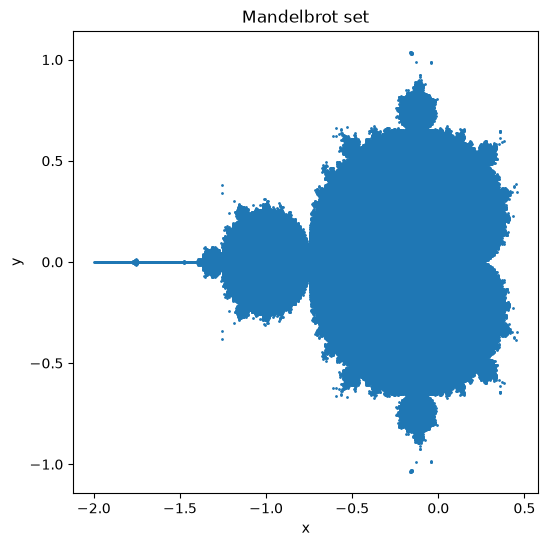

In [198]:
fig = plt.figure(figsize=(6, 6))
plt.title('Mandelbrot set')
plt.scatter(xs, ys, s = 1)
plt.xlabel('x')
plt.ylabel('y')

Text(0, 0.5, 'y')

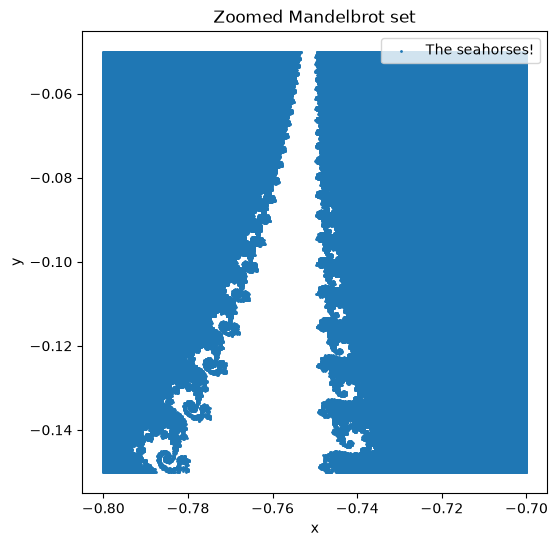

In [199]:
fig = plt.figure(figsize=(6, 6))
plt.title('Zoomed Mandelbrot set')
plt.scatter(xs_zoom, ys_zoom, s = 1, label = 'The seahorses!')
plt.legend(loc = 'upper right')
plt.xlabel('x')
plt.ylabel('y')